K=2  silhouette=0.370
K=3  silhouette=0.230
K=4  silhouette=0.254
K=5  silhouette=0.264
K=6  silhouette=0.253

                           Corner share  Long share  Deep share  Standard 3P%  3PA per game  Deep makes per game
Cluster                                                                                                        
Deep-range creators              0.169       0.146       0.078         0.384         8.757                0.215
Volume above-the-break           0.275       0.066       0.017         0.375         7.527                0.039
Corner / catch-and-shoot         0.372       0.049       0.012         0.407         6.247                0.024
Corner / catch-and-shoot: Desmond Bane, Mikal Bridges, Michael Porter Jr., Isaiah Joe, Sam Hauser
Deep-range creators: Stephen Curry, Trae Young, Jordan Poole, Luka Dončić, LaMelo Ball
Volume above-the-break: Anthony Edwards, Buddy Hield, CJ McCollum, Jayson Tatum, Klay Thompson


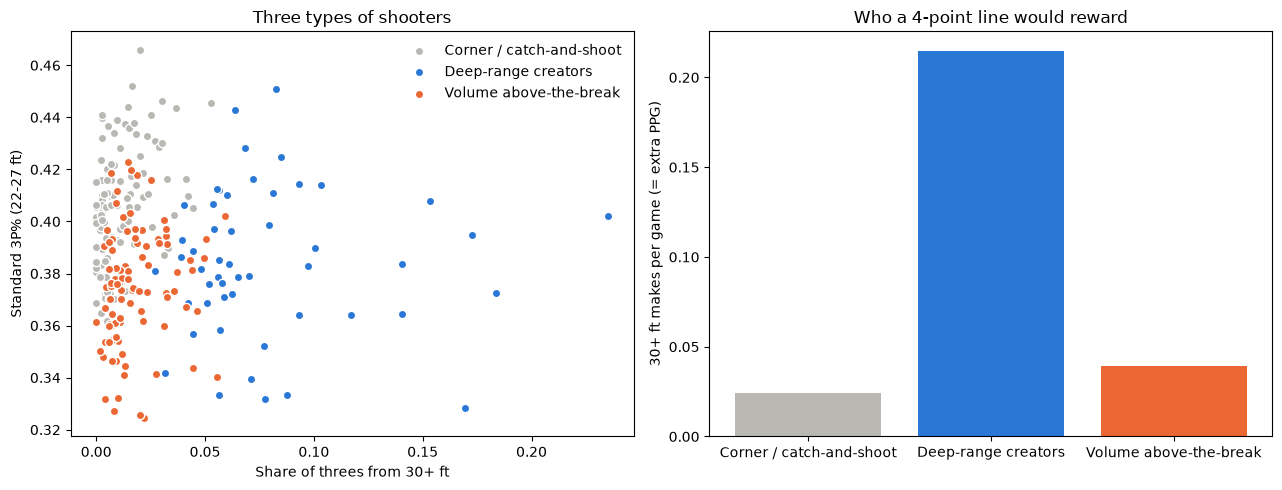

In [1]:
"""K-means: which types of 3-point shooters exist, and which would a 4-point line (30+ ft) reward?
Clusters use shot profile only; deep makes per game is compared afterwards as the outcome.
Run from the folder that contains dataset2_top50_3pm_summary.csv.
"""

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("dataset2_top50_3pm_summary.csv")

# Features (heaves removed: desperation shots say nothing about shot choice)
attempts = df["3PA"] - df["Heaves 3PA"]
df["Corner share"] = df["22-24 ft 3PA"] / attempts
df["Long share"] = df["28-29 ft 3PA"] / attempts
df["Deep share"] = (df["30+ ft 3PA"] - df["Heaves 3PA"]) / attempts
df["Standard 3P%"] = (df["22-24 ft 3PM"] + df["25-27 ft 3PM"]) / (df["22-24 ft 3PA"] + df["25-27 ft 3PA"])
df["3PA per game"] = df["3PA"] / df["GP"]
FEATURES = ["Corner share", "Long share", "Deep share", "Standard 3P%", "3PA per game"]

# Outcome (NOT used for clustering)
df["Deep makes per game"] = (df["30+ ft 3PM"] - df["Heaves 3PM"]) / df["GP"]

X = StandardScaler().fit_transform(df[FEATURES])

# Choosing K: higher silhouette = better separated clusters
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X)
    print(f"K={k}  silhouette={silhouette_score(X, labels):.3f}")

# Final model with K = 3
df["Cluster"] = KMeans(n_clusters=3, n_init=20, random_state=42).fit_predict(X)
profile = df.groupby("Cluster")[FEATURES + ["Deep makes per game"]].mean()
names = {c: "Volume above-the-break" for c in profile.index}
names[profile["Corner share"].idxmax()] = "Corner / catch-and-shoot"
names[profile["Deep share"].idxmax()] = "Deep-range creators"
df["Shooter Type"] = df["Cluster"].map(names)

profile.index = profile.index.map(names)
print("\n", profile.sort_values("Deep makes per game", ascending=False).round(3).to_string())
for name, g in df.groupby("Shooter Type"):
    print(f"{name}: {', '.join(g['Player'].value_counts().index[:5])}")

# Charts: the clusters, and how much each type would gain
colors = {"Deep-range creators": "#2a78d6", "Volume above-the-break": "#eb6834",
          "Corner / catch-and-shoot": "#b9b8b3"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for name, g in df.groupby("Shooter Type"):
    ax1.scatter(g["Deep share"], g["Standard 3P%"], color=colors[name], label=name, edgecolor="white")
ax1.set(xlabel="Share of threes from 30+ ft", ylabel="Standard 3P% (22-27 ft)", title="Three types of shooters")
ax1.legend(frameon=False)
ax2.bar(profile.index, profile["Deep makes per game"], color=[colors[n] for n in profile.index])
ax2.set(ylabel="30+ ft makes per game (= extra PPG)", title="Who a 4-point line would reward")
fig.tight_layout()
fig.savefig("kmeans_results.png", dpi=150)

df[["Season", "Player", "Team", "Shooter Type"] + FEATURES].to_csv("kmeans_shooter_types.csv", index=False)
plt.show()